# Praca z danymi niezbalansowanymi

**Plan notatnika:**
1. Na czym polega problem
2. Dane i podział na zbiór treningowy i testowy
3. Model bez korekty – dlaczego `accuracy` wprowadza w błąd
4. Wagi klas
5. Oversampling i undersampling
6. SMOTE
7. Porównanie metod
8. Podsumowanie i rekomendacje

## 1. Na czym polega problem

W wielu problemach klasyfikacyjnych jedna klasa (**większościowa**) występuje znacznie częściej niż druga (**mniejszościowa**).

**Przykłady:** wykrywanie oszustw (większość transakcji jest uczciwa), diagnostyka rzadkich chorób, predykcja odejść klientów (churn).

**Dlaczego to problem?** Model minimalizuje ogólny błąd, więc może „opłacać się” przewidywać zawsze klasę większościową: `accuracy` jest wysokie, a klasa, na której nam zależy (np. oszustwo), jest całkowicie ignorowana.

## 2. Dane i podział na zbiór treningowy i testowy

Wygenerujemy zbiór z dwiema cechami, w którym tylko ok. 5% obserwacji należy do klasy 1 (mniejszościowej).

Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 3 ("axes.prop_cycle: cycler('color', ['#123D98', '#C21E3C', '#E2A713', '#00AEEF', '#7F3F98'])"): Key axes.prop_cycle: "cycler('color', ['" is not a valid cycler construction: Could not parse "cycler('color', ['": unterminated string literal (detected at line 1) (<unknown>, line 1)
Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 6 ('grid.color: #e0e0e0'): Key grid.color: '' does not look like a color arg


Liczebność klas:
0    1885
1     115
Name: count, dtype: int64

Udziały klas:
0    0.942
1    0.058
Name: proportion, dtype: float64


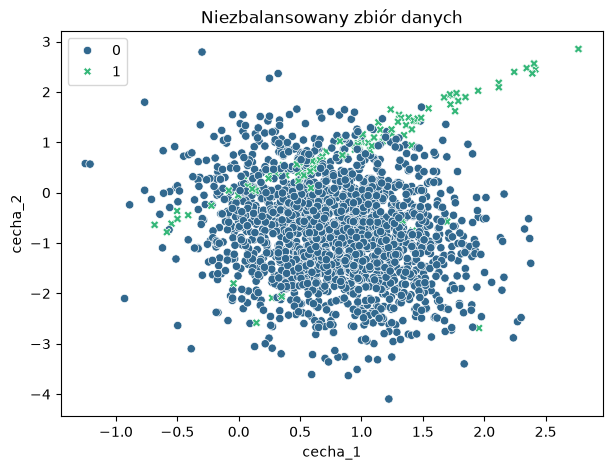

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report)
from sklearn.model_selection import train_test_split
from sklearn.utils import resample

X, y = make_classification(
    n_samples=2000, n_features=2, n_informative=2, n_redundant=0,
    n_clusters_per_class=1, weights=[0.95, 0.05],
    class_sep=0.8, flip_y=0.02, random_state=42)

print('Liczebność klas:')
print(pd.Series(y).value_counts())
print('\nUdziały klas:')
print(pd.Series(y).value_counts(normalize=True).round(3))

plt.figure(figsize=(7, 5))
sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=y, style=y, palette='viridis')
plt.xlabel('cecha_1')
plt.ylabel('cecha_2')
plt.title('Niezbalansowany zbiór danych')
plt.show()

Zbiór dzielimy **przed** jakąkolwiek korektą danych. Użyjemy `stratify=y`, aby obie części miały te same proporcje klas.

> **Ważna zasada:** korekty liczebności klas (oversampling, undersampling, SMOTE) stosujemy **tylko do zbioru treningowego**. Zbiór testowy musi odzwierciedlać rzeczywisty rozkład danych, z którym model spotka się w praktyce. W przeciwnym razie kopie lub syntetyczne obserwacje „wyciekłyby” do testu i zawyżyłyby wynik.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

print('Zbiór treningowy:', np.bincount(y_train))
print('Zbiór testowy:   ', np.bincount(y_test))

Zbiór treningowy: [1319   81]
Zbiór testowy:    [566  34]


## 3. Model bez korekty – dlaczego `accuracy` wprowadza w błąd

Porównajmy model „zawsze klasa 0” (baseline) z regresją logistyczną.

In [3]:
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
print(f'Accuracy baseline (zawsze klasa 0): {baseline.score(X_test, y_test):.3f}')

model_bez_korekty = LogisticRegression(random_state=42).fit(X_train, y_train)
y_pred = model_bez_korekty.predict(X_test)
print(f'Accuracy regresji logistycznej:     {accuracy_score(y_test, y_pred):.3f}\n')
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy baseline (zawsze klasa 0): 0.943
Accuracy regresji logistycznej:     0.947

              precision    recall  f1-score   support

           0       0.95      1.00      0.97       566
           1       0.75      0.09      0.16        34

    accuracy                           0.95       600
   macro avg       0.85      0.54      0.57       600
weighted avg       0.94      0.95      0.93       600



`accuracy` modelu jest **prawie identyczne jak baseline**, który niczego nie wykrywa. Raport pokazuje, że **recall dla klasy 1 jest bardzo niski** – model znajduje tylko niewielką część obserwacji mniejszościowych. Dlatego przy danych niezbalansowanych patrzymy na **precision, recall, F1 i ROC-AUC** dla klasy mniejszościowej (rozdział 3.2).

Zdefiniujmy funkcję, która policzy te miary i zbierze wyniki do wspólnej tabeli:

In [4]:
wyniki = []


def zapisz(nazwa, y_pred, y_proba):
    # Zapisuje metryki na zbiorze testowym (klasa 1 = mniejszościowa).
    wyniki.append({
        'metoda': nazwa,
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred, zero_division=0),
        'recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba),
    })


zapisz('bez korekty', y_pred, model_bez_korekty.predict_proba(X_test)[:, 1])

## 4. Wagi klas

Ta technika **nie zmienia danych**, tylko funkcję kosztu: błąd na klasie mniejszościowej jest „droższy”. Ustawienie `class_weight='balanced'` nadaje wagi odwrotnie proporcjonalne do liczebności klas. Opcję tę ma wiele modeli scikit-learn (`LogisticRegression`, `SVC`, `DecisionTreeClassifier`, `RandomForestClassifier`).

In [5]:
model_wagi = LogisticRegression(random_state=42, class_weight='balanced').fit(X_train, y_train)
y_pred = model_wagi.predict(X_test)
zapisz('wagi klas', y_pred, model_wagi.predict_proba(X_test)[:, 1])

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.79      0.88       566
           1       0.20      0.85      0.32        34

    accuracy                           0.79       600
   macro avg       0.59      0.82      0.60       600
weighted avg       0.94      0.79      0.85       600



Recall klasy 1 bardzo wzrósł, ale kosztem **precision** (więcej fałszywych alarmów) i `accuracy`. To typowy kompromis: odzyskujemy więcej rzadkich przypadków, ale częściej się mylimy co do tych, które oznaczamy jako klasę 1.

## 5. Oversampling i undersampling

Zamiast zmieniać funkcję kosztu, możemy **zmienić liczebność klas w zbiorze treningowym**:

- **Oversampling** – losowe powielanie obserwacji klasy mniejszościowej (do liczebności większościowej). Proste, ale model widzi te same punkty wielokrotnie, co sprzyja przeuczeniu.
- **Undersampling** – losowe usuwanie obserwacji klasy większościowej (do liczebności mniejszościowej). Szybkie, ale tracimy część informacji.

In [6]:
maska_mniej = y_train == 1
X_mniej, y_mniej = X_train[maska_mniej], y_train[maska_mniej]
X_wiecej, y_wiecej = X_train[~maska_mniej], y_train[~maska_mniej]

# Oversampling: losowanie ze zwracaniem do liczebności klasy większościowej
X_mniej_ov, y_mniej_ov = resample(X_mniej, y_mniej, replace=True,
                                  n_samples=len(y_wiecej), random_state=42)
X_over = np.vstack([X_wiecej, X_mniej_ov])
y_over = np.concatenate([y_wiecej, y_mniej_ov])

# Undersampling: losowanie bez zwracania do liczebności klasy mniejszościowej
X_wiecej_un, y_wiecej_un = resample(X_wiecej, y_wiecej, replace=False,
                                    n_samples=len(y_mniej), random_state=42)
X_under = np.vstack([X_wiecej_un, X_mniej])
y_under = np.concatenate([y_wiecej_un, y_mniej])

print('Po oversamplingu: ', np.bincount(y_over))
print('Po undersamplingu:', np.bincount(y_under))

Po oversamplingu:  [1319 1319]
Po undersamplingu: [81 81]


In [7]:
for nazwa, X_k, y_k in [('oversampling', X_over, y_over), ('undersampling', X_under, y_under)]:
    model = LogisticRegression(random_state=42).fit(X_k, y_k)
    zapisz(nazwa, model.predict(X_test), model.predict_proba(X_test)[:, 1])

pd.DataFrame(wyniki).set_index('metoda').round(3)

,accuracy,precision,recall,F1,ROC-AUC
metoda,,,,,
bez korekty,0.947,0.750,0.088,0.158,0.866
wagi klas,0.793,0.196,0.853,0.319,0.874
oversampling,0.792,0.195,0.853,0.317,0.874
undersampling,0.795,0.201,0.882,0.328,0.874


## 6. SMOTE

**SMOTE** (*Synthetic Minority Over-sampling Technique*) to oversampling, który zamiast kopiować obserwacje, tworzy **nowe, syntetyczne**:

1. wybiera obserwację klasy mniejszościowej,
2. znajduje jej `k` najbliższych sąsiadów z tej samej klasy,
3. tworzy nowy punkt na odcinku łączącym ją z losowo wybranym sąsiadem.

Dzięki temu model widzi bardziej zróżnicowane dane niż przy zwykłym powielaniu. SMOTE znajduje się w bibliotece `imbalanced-learn` (jest w pliku `requirements.txt`; samodzielnie instalujemy ją poleceniem `pip install imbalanced-learn`).

Przed SMOTE: [1319   81]
Po SMOTE:    [1319 1319]


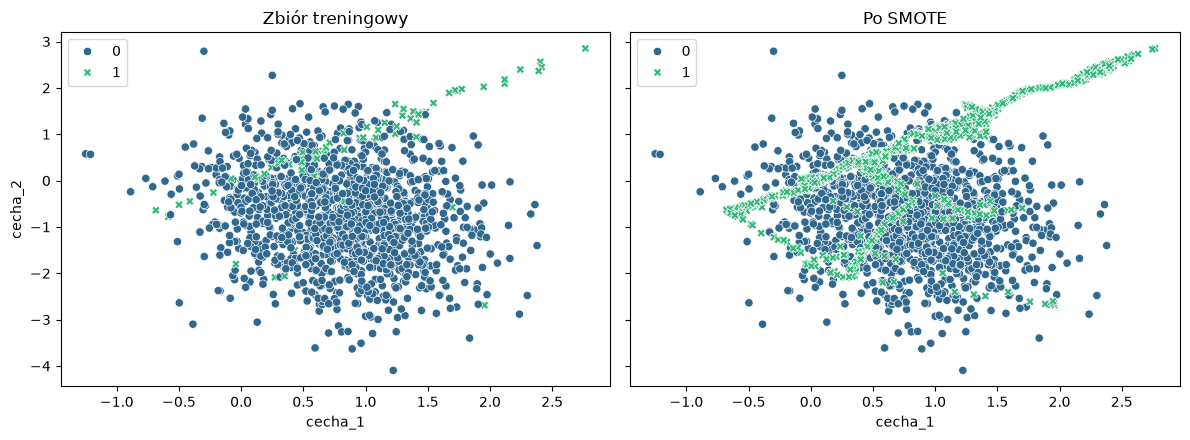

In [8]:
from imblearn.over_sampling import SMOTE

X_smote, y_smote = SMOTE(random_state=42).fit_resample(X_train, y_train)
print('Przed SMOTE:', np.bincount(y_train))
print('Po SMOTE:   ', np.bincount(y_smote))

fig, osie = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True)
for ax, (Xk, yk, tytul) in zip(osie, [(X_train, y_train, 'Zbiór treningowy'),
                                      (X_smote, y_smote, 'Po SMOTE')]):
    sns.scatterplot(x=Xk[:, 0], y=Xk[:, 1], hue=yk, style=yk, palette='viridis', ax=ax)
    ax.set_title(tytul)
    ax.set_xlabel('cecha_1')
    ax.set_ylabel('cecha_2')
plt.tight_layout()
plt.show()

In [9]:
model_smote = LogisticRegression(random_state=42).fit(X_smote, y_smote)
zapisz('SMOTE', model_smote.predict(X_test), model_smote.predict_proba(X_test)[:, 1])

> **Uwaga:** przy walidacji krzyżowej lub strojeniu hiperparametrów SMOTE (i inne metody resamplingu) należy umieścić **wewnątrz potoku** z `imblearn.pipeline.Pipeline`. Wtedy w każdym przebiegu walidacji korekta dotyczy tylko części treningowej. Zwykły `Pipeline` ze scikit-learn nie obsługuje kroków zmieniających liczbę obserwacji.

## 7. Porównanie metod

Dla porównania dodajmy jeszcze **zmianę progu decyzyjnego** – model bez korekty, ale z obniżonym progiem (domyślnie obserwacja trafia do klasy 1, gdy prawdopodobieństwo wynosi co najmniej 0,5).

In [10]:
proba = model_bez_korekty.predict_proba(X_test)[:, 1]
zapisz('bez korekty, próg 0,1', (proba >= 0.1).astype(int), proba)

tabela = pd.DataFrame(wyniki).set_index('metoda').round(3)
tabela

,accuracy,precision,recall,F1,ROC-AUC
metoda,,,,,
bez korekty,0.947,0.750,0.088,0.158,0.866
wagi klas,0.793,0.196,0.853,0.319,0.874
oversampling,0.792,0.195,0.853,0.317,0.874
undersampling,0.795,0.201,0.882,0.328,0.874
SMOTE,0.797,0.203,0.882,0.330,0.873
"bez korekty, próg 0,1",0.880,0.279,0.706,0.400,0.866


Wnioski z tabeli:

- **`accuracy` jest najwyższe dla modelu bez korekty**, choć ten model prawie niczego nie wykrywa. To dowód, że `accuracy` jest tu mylącym kryterium.
- Wszystkie metody korekty dają **podobny efekt**: wyraźnie wyższy recall i niższy precision. Wynika to z tego, że dla prostego modelu liniowego zmieniają one w istocie **położenie granicy decyzyjnej** (czyli kompromis między precision a recall), a nie „wiedzę” modelu.
- **ROC-AUC** (ocena rankingu prawdopodobieństw, niezależna od progu) jest dla wszystkich wariantów niemal taki sam. Sam **obniżony próg** (bez zmiany danych i modelu) daje tu nawet lepszy kompromis: najwyższe F1 i wyższe `accuracy` niż wagi czy resampling, przy niższym recall.
- Różnice między oversamplingiem, undersamplingiem, SMOTE i wagami są niewielkie i mieszczą się w granicach losowości jednego podziału danych. SMOTE i resampling bywają bardziej przydatne dla modeli, które nie mają parametru `class_weight` lub nie zwracają prawdopodobieństw.

## 8. Podsumowanie i rekomendacje

| Technika | Zalety | Wady |
|---|---|---|
| **Wagi klas** | nie zmieniają danych, szybkie, jeden parametr | nie każdy model ma tę opcję |
| **Zmiana progu decyzyjnego** | bez ponownego uczenia modelu, pełna kontrola nad kompromisem precision/recall | wymaga modelu zwracającego prawdopodobieństwa |
| **Oversampling** | prosty | powielone obserwacje sprzyjają przeuczeniu |
| **Undersampling** | szybki (mniej danych) | tracimy informacje z klasy większościowej |
| **SMOTE** | bardziej zróżnicowane dane niż przy powielaniu | może tworzyć szum, gdy klasy się nakładają; wymaga `imbalanced-learn` |

**Praktyczne wskazówki:**

1. Zaczynamy od właściwych **metryk** (precision, recall, F1, ROC-AUC) i modelu bazowego, a nie `accuracy`.
2. Najpierw próbujemy **wag klas** i/lub **zmiany progu**, bo to najprostsze rozwiązania.
3. Resampling (w tym SMOTE) rozważamy, gdy to nie wystarcza lub model nie obsługuje wag. **Stosujemy go tylko do zbioru treningowego**, a w walidacji krzyżowej – wewnątrz potoku `imblearn`.
4. Wybór kompromisu między precision a recall wynika z **kosztów błędów w danym problemie**: przy wykrywaniu choroby wolimy wysoki recall, przy filtrowaniu spamu – wysoki precision.